# Esperimento frange di intensità luminosa di interferenza e diffrazione

#### Importiamo le librerie necessarie e definiamo le costanti

In [1]:
import matplotlib.pyplot as plt
import math
import numpy as np

In [2]:
B = 20
I0=400
alfa = 1.50
delta = 5.20
rng=np.random.default_rng(3297894501)

##### Definiamo le funzioni del modello dividendo la funzione mu in due sottofunzioni e calcoliamo l'inviluppo

In [3]:
x = np.linspace(-5.0, 5.0, 161)

def E(array1):
    return np.sinc(alfa*array1/np.pi)**2

def C(array2):
    return (np.cos(delta*array2))**2

def Mu(array1):
    return B+I0*E(array1)*C(array1)

inviluppo=B+I0*E(x)

##### Controlliamo che il modello si comporti coerentemente con le aspettative fisiche

In [4]:
if np.all(Mu(x)>=0) and np.all(np.isfinite(Mu(x))) and np.all(Mu(x)==Mu(-x)) and Mu(0)==B+I0:
    print(True)

True


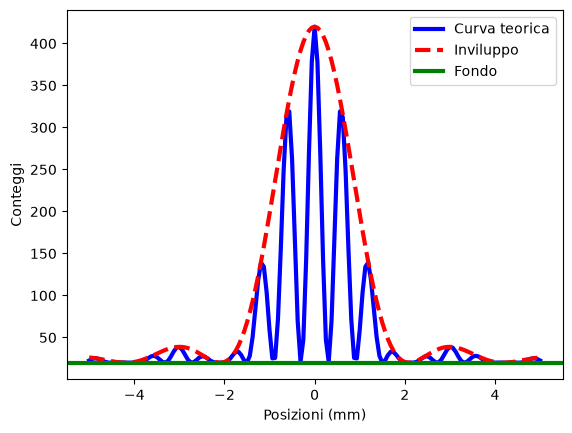

In [5]:
grafico, asse =plt.subplots()
asse.plot(x,Mu(x), "b-", lw=3, label="Curva teorica")
asse.plot(x,inviluppo, "r--", lw=3, label="Inviluppo")
asse.axhline(B, color="g", lw=3, label="Fondo")
asse.set(xlabel="Posizioni (mm)", ylabel="Conteggi")
asse.legend()

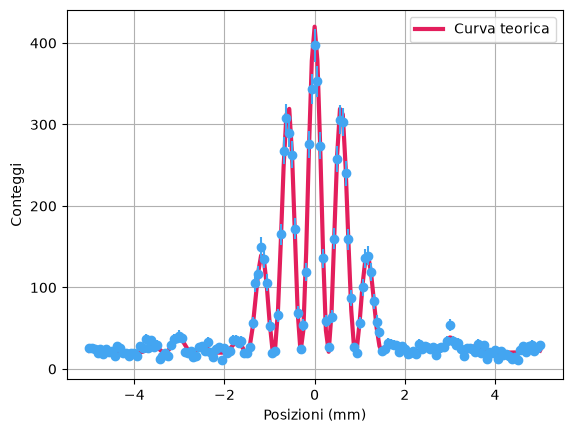

In [6]:
n=rng.poisson(Mu(x))
errori=[]
for ni in n:
    if ni==0:
        errori.append(1)
    else:
        errori.append(ni**0.5)
errors=np.array(errori)
grafico, asse =plt.subplots()
asse.plot(x,Mu(x), "-",color="#e31e5c", lw=3, label="Curva teorica")
#asse.plot(x,inviluppo, "r--", lw=3, label="Inviluppo")
#asse.axhline(B, color="g", lw=3, label="Fondo")
asse.errorbar(x,n,yerr=errors, fmt='o', color="#43a5f1")
asse.set(xlabel="Posizioni (mm)", ylabel="Conteggi")
asse.grid()
asse.legend()

In [7]:
Nc=np.sum(n[abs(x) < 1.2])
mu_c=np.sum(Mu(x[abs(x) < 1.2]))
statistica=(Nc-mu_c)/(mu_c**0.5)
print(statistica)

-1.461869645066099


In [8]:
m=30000
def generatore(array):
    ni=rng.poisson(Mu(array))
    Nc_i=np.sum(ni[abs(array) < 1.2])
    return Nc_i

risultati_=[]
for i in range(m):
    risultati_.append(generatore(x))
risultati=np.array(risultati_)
media=risultati.mean()
dev_std=risultati.std(ddof=1)
dev_std_med=dev_std/(m**0.5)
scarto_rel=media-mu_c
rapporto_deviazioni=dev_std/(mu_c**0.5)

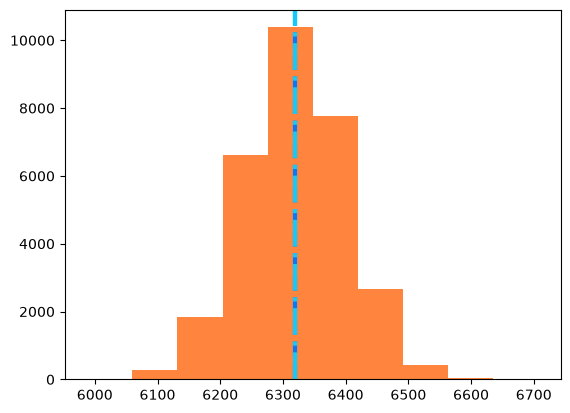

In [9]:
figura1, assi =plt.subplots()
assi.hist(risultati, color="#FF853F")
assi.axvline(media, color="#007BFF", lw=3, linestyle="--")
assi.axvline(mu_c, color="#10cBFb", lw=3, linestyle="-.")

In [20]:
y= np.array(Mu(x))
file=open("data_file.txt", "w")
for i in range(len(x)):
    tupla=(i,float(x[i]), float(y[i]), float(errori[i]))
    file.writelines(str(tupla)+"\n")
file.close()
nuovo=open("data_file.txt", "r")
print(nuovo.read())

(0, -5.0, 22.618444455084795, 5.0990195135927845)
(1, -4.9375, 24.347396125172573, 5.0990195135927845)
(2, -4.875, 25.23808452572966, 5.0)
(3, -4.8125, 24.91592988538138, 4.358898943540674)
(4, -4.75, 23.612401373877645, 4.898979485566356)
(5, -4.6875, 21.975311492984627, 4.242640687119285)
(6, -4.625, 20.676888642361597, 4.898979485566356)
(7, -4.5625, 20.063615598711387, 4.58257569495584)
(8, -4.5, 20.04622715360848, 4.69041575982343)
(9, -4.4375, 20.262594109889108, 4.0)
(10, -4.375, 20.371716613568278, 5.291502622129181)
(11, -4.3125, 20.267899777238295, 5.0990195135927845)
(12, -4.25, 20.081761206762238, 4.47213595499958)
(13, -4.1875, 20.00003622570007, 4.47213595499958)
(14, -4.125, 20.070060796629445, 4.0)
(15, -4.0625, 20.160268068310316, 4.47213595499958)
(16, -4.0, 20.11913892041233, 4.358898943540674)
(17, -3.9375, 20.00463463665006, 4.0)
(18, -3.875, 20.173674636174997, 5.291502622129181)
(19, -3.8125, 21.10073466657085, 5.0990195135927845)
(20, -3.75, 22.99564884052829, 6